# Self-lensing observable-space recovery

This experiment draws 10,000 self-lensing configurations across five representative companion-star types. The lensing observables and companion properties are treated as exact, so the recovery scatter reflects only the finite observable-space nearest-neighbour approximation.

In [7]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.colors import LogNorm, Normalize

from estimation import (
    calc_self_lensing_observable_space,
    estimate_lens_mass_and_orbital_period_batch,
)

N_SYSTEMS = 10_000
N_NEIGHBORS = 128
RANDOM_SEED = 20260824

# Main-sequence companion masses [Msun]. Radius and temperature are derived
# by selflensing.gp.PhysicalRelations, rather than specified independently.
STELLAR_MODELS = (
    (r"0.5 $M_\odot$", 0.5),
    (r"0.7 $M_\odot$", 0.7),
    (r"1.0 $M_\odot$", 1.0),
    (r"1.5 $M_\odot$", 1.5),
    (r"2.0 $M_\odot$", 2.0),
    (r"3.0 $M_\odot$", 3.0),
    (r"5.0 $M_\odot$", 5.0),
    (r"8.0 $M_\odot$", 8.0),
    (r"12 $M_\odot$", 12.0),
    (r"20 $M_\odot$", 20.0),
)
N_PER_MODEL = N_SYSTEMS // len(STELLAR_MODELS)
assert N_PER_MODEL * len(STELLAR_MODELS) == N_SYSTEMS


In [ ]:
truth_samples = []
for model_index, (label, mass) in enumerate(STELLAR_MODELS):
    accepted = {
        name: []
        for name in ("peak_amplification_ppm", "crossing_time_hr", "lens_mass_msun", "orbital_period_yr")
    }
    accepted_count = 0
    attempt = 0
    while accepted_count < N_PER_MODEL:
        sample = calc_self_lensing_observable_space(
            sample_size=N_PER_MODEL,
            random_seed=RANDOM_SEED + 10_000 * model_index + attempt,
            companion_mass_msun=mass,
        )
        valid_indices = np.flatnonzero(sample["valid"])
        needed = N_PER_MODEL - accepted_count
        accepted_indices = valid_indices[:needed]
        for name in accepted:
            accepted[name].append(sample[name][accepted_indices])
        accepted_count += len(accepted_indices)
        attempt += 1
        if attempt > 20:
            raise RuntimeError(f"Could not generate {N_PER_MODEL} valid {label} systems")
    truth_samples.append(
        pd.DataFrame(
            {
                "stellar_model": label,
                "companion_mass_msun": sample["companion_mass_msun"],
                "companion_radius_rsun": sample["companion_radius_rsun"],
                "companion_teff_k": sample["companion_teff_k"],
                "peak_amplification_ppm": np.concatenate(accepted["peak_amplification_ppm"]),
                "crossing_time_hr": np.concatenate(accepted["crossing_time_hr"]),
                "true_lens_mass_msun": np.concatenate(accepted["lens_mass_msun"]),
                "true_orbital_period_yr": np.concatenate(accepted["orbital_period_yr"]),
            }
        )
    )

systems = pd.concat(truth_samples, ignore_index=True)
systems.shape


In [ ]:
estimated_groups = []
for model_index, (label, mass) in enumerate(STELLAR_MODELS):
    group = systems.loc[systems["stellar_model"] == label].copy()
    estimates = estimate_lens_mass_and_orbital_period_batch(
        group["peak_amplification_ppm"].to_numpy(),
        group["crossing_time_hr"].to_numpy(),
        n_neighbors=N_NEIGHBORS,
        sample_size=N_SYSTEMS,
        random_seed=RANDOM_SEED + 100 + model_index,
        companion_mass_msun=mass,
    )
    group["estimated_lens_mass_msun"] = estimates["lens_mass_msun"]
    group["lens_mass_uncertainty_msun"] = estimates["lens_mass_uncertainty_msun"]
    group["estimated_orbital_period_yr"] = estimates["orbital_period_yr"]
    group["orbital_period_uncertainty_yr"] = estimates["orbital_period_uncertainty_yr"]
    estimated_groups.append(group)

systems = pd.concat(estimated_groups, ignore_index=True)


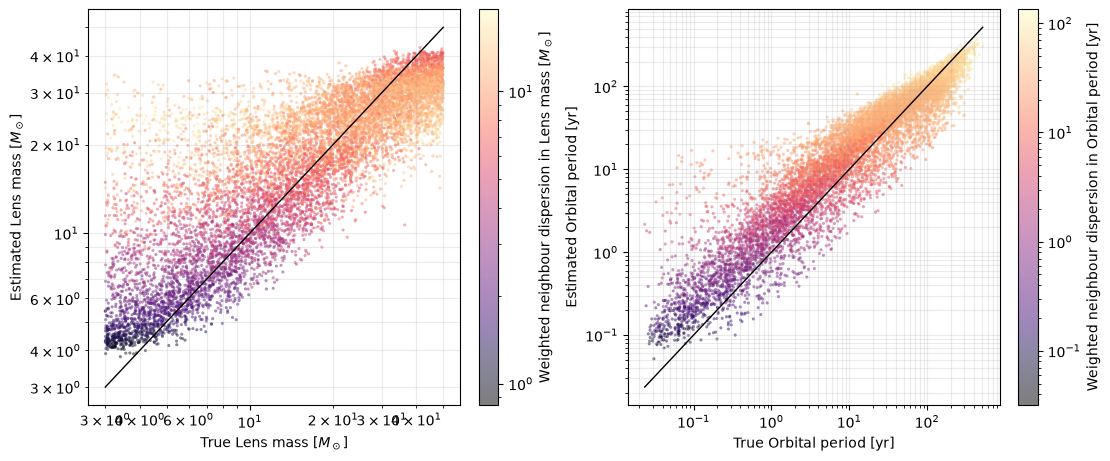

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)

plots = (
    ("true_lens_mass_msun", "estimated_lens_mass_msun", "lens_mass_uncertainty_msun", r"Lens mass [$M_\odot$]"),
    ("true_orbital_period_yr", "estimated_orbital_period_yr", "orbital_period_uncertainty_yr", "Orbital period [yr]"),
)
for axis, (truth_column, estimate_column, uncertainty_column, label) in zip(axes, plots):
    uncertainty = systems[uncertainty_column].to_numpy()
    positive_uncertainty = uncertainty[uncertainty > 0.0]
    norm = (
        LogNorm(vmin=positive_uncertainty.min(), vmax=positive_uncertainty.max())
        if len(positive_uncertainty)
        else Normalize(vmin=0.0, vmax=1.0)
    )
    scatter = axis.scatter(
        systems[truth_column],
        systems[estimate_column],
        c=uncertainty,
        s=5,
        alpha=0.5,
        cmap="magma",
        norm=norm,
        linewidths=0,
    )
    limits = np.array([systems[truth_column].min(), systems[truth_column].max(),
                       systems[estimate_column].min(), systems[estimate_column].max()])
    lower, upper = limits.min(), limits.max()
    axis.plot([lower, upper], [lower, upper], color="black", lw=1, label="exact recovery")
    axis.set_xscale("log")
    axis.set_yscale("log")
    axis.set_xlabel(f"True {label}")
    axis.set_ylabel(f"Estimated {label}")
    axis.grid(True, which="both", alpha=0.25)
    fig.colorbar(scatter, ax=axis, label=f"Weighted neighbour dispersion in {label}")

plt.show()


In [ ]:
# Full-light-curve photometry-only fits from the simulation campaign.
from pathlib import Path

fitted_results_path = next(
    path
    for path in (Path("data/fitted_timeseries.gz"), Path("../data/fitted_timeseries.gz"))
    if path.exists()
)
photometry_results = pd.read_pickle(fitted_results_path)

def scalar_number(value):
    try:
        array = np.asarray(value)
        return float(array.reshape(-1)[0]) if array.size == 1 else np.nan
    except (TypeError, ValueError):
        return np.nan

photometry_only = photometry_results.loc[:, [
    "pristine_id",
    "Macc",
    "Porb",
    "prefit_fitted_Macc",
    "prefit_fitted_porb",
]].copy()
for column in photometry_only.columns.drop("pristine_id"):
    photometry_only[column] = photometry_only[column].map(scalar_number)
# The stored orbital periods are in days; use years to match the earlier plots.
photometry_only[["Porb", "prefit_fitted_porb"]] /= 365.25

# A photometry-only pre-fit is shared across every RV strategy for a system.
photometry_only = photometry_only.drop_duplicates("pristine_id")
photometry_only = photometry_only.replace([np.inf, -np.inf], np.nan).dropna()
photometry_only = photometry_only.loc[(photometry_only.drop(columns="pristine_id") > 0.0).all(axis=1)]
len(photometry_only)


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)

photometry_plots = (
    ("Macc", "prefit_fitted_Macc", r"Lens mass [$M_\odot$]"),
    ("Porb", "prefit_fitted_porb", "Orbital period [yr]"),
)
for axis, (truth_column, fitted_column, label) in zip(axes, photometry_plots):
    axis.scatter(
        photometry_only[truth_column],
        photometry_only[fitted_column],
        s=7,
        alpha=0.35,
        color="#0072B2",
        linewidths=0,
    )
    lower = min(photometry_only[truth_column].min(), photometry_only[fitted_column].min())
    upper = max(photometry_only[truth_column].max(), photometry_only[fitted_column].max())
    axis.plot([lower, upper], [lower, upper], color="black", lw=1)
    axis.set_xscale("log")
    axis.set_yscale("log")
    axis.set_xlabel(f"True {label}")
    axis.set_ylabel(f"Photometry-only fitted {label}")
    axis.grid(True, which="both", alpha=0.25)

fig.suptitle(f"Full light-curve, photometry-only pre-fits ({len(photometry_only):,} systems)")
plt.show()
